Using device: cpu
Loading model...


config.json:   0%|          | 0.00/4.61k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  982MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  982MB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/120 [00:00<?, ?B/s]

Model loaded successfully!

Upload an image:


Saving DOG IMAGE DL.webp to DOG IMAGE DL.webp
Selected image: DOG IMAGE DL.webp


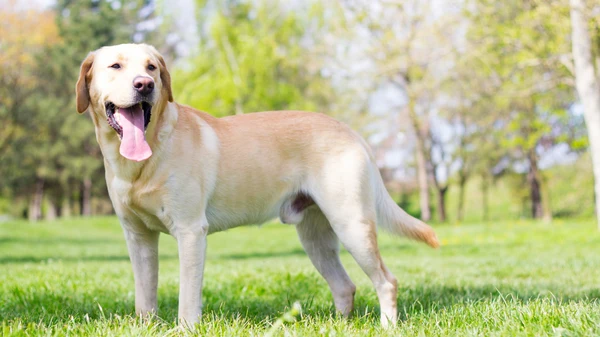

[transformers] We strongly recommend passing in an `attention_mask` since your input_ids may be padded. See https://huggingface.co/docs/transformers/troubleshooting#incorrect-output-when-padding-tokens-arent-masked.
You may ignore this warning if your `pad_token_id` (50256) is identical to the `bos_token_id` (50256), `eos_token_id` (50256), or the `sep_token_id` (None), and your input is not padded.



Generated Caption:
a large brown dog standing in a grassy field 


In [ ]:

import torch
from transformers import VisionEncoderDecoderModel
from transformers import ViTImageProcessor
from transformers import AutoTokenizer
from PIL import Image
from google.colab import files

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)

model_name = "nlpconnect/vit-gpt2-image-captioning"

print("Loading model...")

model = VisionEncoderDecoderModel.from_pretrained(model_name)

processor = ViTImageProcessor.from_pretrained(model_name)

tokenizer = AutoTokenizer.from_pretrained(model_name)

model = model.to(device)

model.eval()

print("Model loaded successfully!")

print("\nUpload an image:")

uploaded = files.upload()

image_path = list(uploaded.keys())[0]

print("Selected image:", image_path)

image = Image.open(image_path).convert("RGB")

display(image)


pixel_values = processor(
    images=image,
    return_tensors="pt"
).pixel_values

pixel_values = pixel_values.to(device)


with torch.no_grad():

    output_ids = model.generate(
        pixel_values,
        max_length=30,
        num_beams=4,
        early_stopping=True
    )


caption = tokenizer.decode(
    output_ids[0],
    skip_special_tokens=True
)


print("\nGenerated Caption:")
print(caption)